# Interactive SVT disk acceptance analysis

This notebook steers the tested command-line analysis while keeping every selection visible. It does **not** duplicate the reduction formulas. The heavy work remains in `reduce_disk_acceptance.py`, validation in `validate_disk_acceptance.py`, and standard figures in `plot_disk_acceptance.py`.

The integrated acceptance is the fraction of selected generated primary $\pi^+$ particles with at least one directly associated `TrackerEndcapHits` entry on a disk. The 2D maps use a straight-line projection to the nominal disk plane so missing-hit particles also have coordinates.

## 1. Imports and paths

Run this notebook with the `tracking` conda environment. Paths are resolved relative to this notebook when possible.

In [1]:
from pathlib import Path
import json
import shlex
import subprocess
import sys

import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm
import numpy as np
import pandas as pd
from IPython.display import Image, display

SCRIPT_DIR = Path.cwd()
if not (SCRIPT_DIR / 'reduce_disk_acceptance.py').is_file():
    candidate = Path('proj_svt_disk_tiling/simrec/acc_study').resolve()
    if (candidate / 'reduce_disk_acceptance.py').is_file():
        SCRIPT_DIR = candidate
    else:
        raise FileNotFoundError('Run from the notebook directory or the EPIC repository root.')

CAMPAIGN_ROOT = Path('/pscratch/sd/p/pdatta/svt_disk_tiling/acc_study/acceptance_v1')
print('Analysis scripts:', SCRIPT_DIR)
print('Campaign:', CAMPAIGN_ROOT)

Analysis scripts: /global/cfs/cdirs/m3763/pdatta/epic/proj_svt_disk_tiling/simrec/acc_study
Campaign: /pscratch/sd/p/pdatta/svt_disk_tiling/acc_study/acceptance_v1


## 2. Steering configuration

Edit only this cell for normal use. Ranges are half-open: `MIN <= value < MAX`. `ABS_ETA_RANGE=(1.0, 2.5)` applies $1.0\leq\eta<2.5$ on the positive side and $-2.5<\eta\leq-1.0$ on the negative side. Set either range to `None` for no additional cut.

The defaults are deliberately a small test. Set both file/event limits to `None` for production. Use a new `SELECTION_TAG` whenever cuts change so previous results are not overwritten.

In [ ]:
# Bounded-memory reading
STEP_SIZE = 5_000
MAX_FILES_PER_SIDE = None            # Set to None for all 50 files/side
STOP_EVENTS_PER_FILE = None      # Set to None for all 100,000 events/file

# One-time extraction location. Reuse this directory for many selections.
EXTRACTION_TAG = 'acceptance_v1'
EXTRACTED_ROOT = SCRIPT_DIR / 'extracted' / EXTRACTION_TAG

RUN_EXTRACTION = False

In [26]:
if RUN_EXTRACTION:
    if EXTRACTED_ROOT.exists():
        raise FileExistsError(
            f'{EXTRACTED_ROOT} already exists. Reuse it or change EXTRACTION_TAG.'
        )
    subprocess.run(extract_command, check=True)
else:
    print('Extraction not run. Reusing existing shards if available.')

vz_000mm_eta_m3p8_to_m0p6: extracting 50 files
  [01/50] particles_vz_000mm_eta_m3p8_to_m0p6_chunk_001_n100000.npz: 100,000 particles, 4,983,176 bytes
  [02/50] particles_vz_000mm_eta_m3p8_to_m0p6_chunk_002_n100000.npz: 100,000 particles, 4,981,081 bytes
  [03/50] particles_vz_000mm_eta_m3p8_to_m0p6_chunk_003_n100000.npz: 100,000 particles, 4,993,939 bytes
  [04/50] particles_vz_000mm_eta_m3p8_to_m0p6_chunk_004_n100000.npz: 100,000 particles, 4,988,527 bytes
  [05/50] particles_vz_000mm_eta_m3p8_to_m0p6_chunk_005_n100000.npz: 100,000 particles, 4,993,012 bytes
  [06/50] particles_vz_000mm_eta_m3p8_to_m0p6_chunk_006_n100000.npz: 100,000 particles, 4,981,336 bytes
  [07/50] particles_vz_000mm_eta_m3p8_to_m0p6_chunk_007_n100000.npz: 100,000 particles, 4,989,423 bytes
  [08/50] particles_vz_000mm_eta_m3p8_to_m0p6_chunk_008_n100000.npz: 100,000 particles, 4,982,915 bytes
  [09/50] particles_vz_000mm_eta_m3p8_to_m0p6_chunk_009_n100000.npz: 100,000 particles, 4,983,665 bytes
  [10/50] particl

In [30]:
# Physics selection applied later to the extracted particle rows.
VERTICES_MM = [0]                 # Allowed values: 0, -10, +10
ABS_ETA_RANGE = (0.9,2.0)              # Example: (1.0, 2.5)
MOMENTUM_RANGE_GEV = (10.0, 20.0)         # Example: (1.0, 10.0)

# Spatial map definition
BIN_SIZE_MM = 10.0
XY_LIMIT_MM = 450.0
MINIMUM_BIN_DENOMINATOR = 50

# A descriptive tag prevents selections from overwriting each other.
SELECTION_TAG = 'acceptance_v1'
OUTPUT_DIR = SCRIPT_DIR / 'results' / SELECTION_TAG

# Expensive ROOT extraction and fast reductions require separate opt-ins.
RUN_REDUCTION = True
RUN_VALIDATION = True
RUN_STANDARD_PLOTS = True

## 3. Build and review the reduction command

This cell prints both exact commands. `RUN_EXTRACTION` reads ROOT and writes reusable per-primary shards without eta or momentum cuts. `RUN_REDUCTION` applies the displayed cuts to those shards and is safe to repeat into a new `SELECTION_TAG`.

In [31]:
reduced_dir = OUTPUT_DIR / 'reduced'
plot_dir = OUTPUT_DIR / 'plots'

extract_command = [
    sys.executable, str(SCRIPT_DIR / 'extract_disk_particles.py'),
    '--campaign-root', str(CAMPAIGN_ROOT),
    '--output-dir', str(EXTRACTED_ROOT),
    '--vertices', *[str(value) for value in VERTICES_MM],
    '--step-size', str(STEP_SIZE),
]
if MAX_FILES_PER_SIDE is not None:
    extract_command += ['--max-files-per-side', str(MAX_FILES_PER_SIDE)]
if STOP_EVENTS_PER_FILE is not None:
    extract_command += ['--stop-events-per-file', str(STOP_EVENTS_PER_FILE)]

reduce_command = [
    sys.executable, str(SCRIPT_DIR / 'reduce_disk_acceptance.py'),
    '--extracted-root', str(EXTRACTED_ROOT),
    '--output-dir', str(reduced_dir),
    '--vertices', *[str(value) for value in VERTICES_MM],
    '--step-size', str(STEP_SIZE),
    '--bin-size-mm', str(BIN_SIZE_MM),
    '--xy-limit-mm', str(XY_LIMIT_MM),
]
if ABS_ETA_RANGE is not None:
    reduce_command += ['--abs-eta-range', *map(str, ABS_ETA_RANGE)]
if MOMENTUM_RANGE_GEV is not None:
    reduce_command += ['--momentum-range-gev', *map(str, MOMENTUM_RANGE_GEV)]
print('One-time extraction:')
print(shlex.join(extract_command))
print('\nRepeatable reduction:')
print(shlex.join(reduce_command))

One-time extraction:
/global/homes/p/pdatta/.conda/envs/tracking/bin/python /global/cfs/cdirs/m3763/pdatta/epic/proj_svt_disk_tiling/simrec/acc_study/extract_disk_particles.py --campaign-root /pscratch/sd/p/pdatta/svt_disk_tiling/acc_study/acceptance_v1 --output-dir /global/cfs/cdirs/m3763/pdatta/epic/proj_svt_disk_tiling/simrec/acc_study/extracted/acceptance_v1 --vertices 0 --step-size 5000

Repeatable reduction:
/global/homes/p/pdatta/.conda/envs/tracking/bin/python /global/cfs/cdirs/m3763/pdatta/epic/proj_svt_disk_tiling/simrec/acc_study/reduce_disk_acceptance.py --extracted-root /global/cfs/cdirs/m3763/pdatta/epic/proj_svt_disk_tiling/simrec/acc_study/extracted/acceptance_v1 --output-dir /global/cfs/cdirs/m3763/pdatta/epic/proj_svt_disk_tiling/simrec/acc_study/results/acceptance_v1/reduced --vertices 0 --step-size 5000 --bin-size-mm 10.0 --xy-limit-mm 450.0 --abs-eta-range 0.9 2.0 --momentum-range-gev 10.0 20.0


In [32]:
if RUN_REDUCTION:
    if reduced_dir.exists():
        raise FileExistsError(
            f'{reduced_dir} already exists. Change SELECTION_TAG rather than overwriting it.'
        )
    subprocess.run(reduce_command, check=True)
else:
    print('Reduction not run. Review settings, then set RUN_REDUCTION=True.')

vz_000mm_eta_m3p8_to_m0p6: reducing 50 extracted shards
  [01/50] particles_vz_000mm_eta_m3p8_to_m0p6_chunk_001_n100000.npz: 17,623 selected
  [02/50] particles_vz_000mm_eta_m3p8_to_m0p6_chunk_002_n100000.npz: 17,485 selected
  [03/50] particles_vz_000mm_eta_m3p8_to_m0p6_chunk_003_n100000.npz: 17,370 selected
  [04/50] particles_vz_000mm_eta_m3p8_to_m0p6_chunk_004_n100000.npz: 17,373 selected
  [05/50] particles_vz_000mm_eta_m3p8_to_m0p6_chunk_005_n100000.npz: 17,725 selected
  [06/50] particles_vz_000mm_eta_m3p8_to_m0p6_chunk_006_n100000.npz: 17,623 selected
  [07/50] particles_vz_000mm_eta_m3p8_to_m0p6_chunk_007_n100000.npz: 17,524 selected
  [08/50] particles_vz_000mm_eta_m3p8_to_m0p6_chunk_008_n100000.npz: 17,308 selected
  [09/50] particles_vz_000mm_eta_m3p8_to_m0p6_chunk_009_n100000.npz: 17,600 selected
  [10/50] particles_vz_000mm_eta_m3p8_to_m0p6_chunk_010_n100000.npz: 17,845 selected
  [11/50] particles_vz_000mm_eta_m3p8_to_m0p6_chunk_011_n100000.npz: 17,550 selected
  [12/50]

## 4. Discover and validate reduced results

Validation checks array shapes, unique counting relationships, `numerator <= denominator`, and `hit + missing = denominator` in every stored bin. Expected event totals are intentionally not hard-coded here because eta and momentum cuts change them.

In [33]:
npz_files = sorted(reduced_dir.glob('disk_acceptance_vz_*.npz'))
csv_files = sorted(reduced_dir.glob('disk_acceptance_vz_*.csv'))
print(f'Found {len(npz_files)} NPZ and {len(csv_files)} CSV files in {reduced_dir}')

if RUN_VALIDATION and npz_files:
    validate_command = [sys.executable, str(SCRIPT_DIR / 'validate_disk_acceptance.py'),
                        *map(str, npz_files)]
    print(shlex.join(validate_command))
    subprocess.run(validate_command, check=True)
elif RUN_VALIDATION:
    print('No reduced results found. Run the reduction or point OUTPUT_DIR to an existing selection.')

Found 1 NPZ and 1 CSV files in /global/cfs/cdirs/m3763/pdatta/epic/proj_svt_disk_tiling/simrec/acc_study/results/acceptance_v1/reduced
/global/homes/p/pdatta/.conda/envs/tracking/bin/python /global/cfs/cdirs/m3763/pdatta/epic/proj_svt_disk_tiling/simrec/acc_study/validate_disk_acceptance.py /global/cfs/cdirs/m3763/pdatta/epic/proj_svt_disk_tiling/simrec/acc_study/results/acceptance_v1/reduced/disk_acceptance_vz_000mm.npz
PASS: /global/cfs/cdirs/m3763/pdatta/epic/proj_svt_disk_tiling/simrec/acc_study/results/acceptance_v1/reduced/disk_acceptance_vz_000mm.npz


## 5. Integrated acceptance tables

`n_with_hit` counts unique generated particles, while `n_raw_hits` may be larger because one particle can leave multiple hits on a disk.

In [34]:
if csv_files:
    integrated = pd.concat([pd.read_csv(path) for path in csv_files], ignore_index=True)
    display(integrated[[
        'vertex_z_mm', 'side', 'disk', 'system', 'layer', 'nominal_z_mm',
        'n_generated', 'n_with_hit', 'n_raw_hits', 'acceptance',
        'wilson68_low', 'wilson68_high', 'projection_residual_rms_mm',
    ]])
else:
    integrated = pd.DataFrame()
    print('No integrated CSV files are available yet.')

,vertex_z_mm,side,disk,system,layer,nominal_z_mm,n_generated,n_with_hit,n_raw_hits,acceptance,wilson68_low,wilson68_high,projection_residual_rms_mm
0,0,negative,ED0,68,1,-250.0,879228,753495,1021194,0.856996,0.856622,0.857369,1.725963
1,0,negative,ED1,69,1,-450.0,879228,767270,952827,0.872663,0.872307,0.873018,2.768902
2,0,negative,ED2,70,2,-650.0,879228,581468,709811,0.661339,0.660834,0.661844,3.915769
3,0,negative,ED3,70,3,-850.0,879228,401165,503064,0.456270,0.455738,0.456801,5.259176
4,0,negative,ED4,70,4,-1020.0,879228,272450,360921,0.309874,0.309381,0.310368,6.558246
5,0,positive,HD0,77,1,250.0,883170,753926,1022570,0.853659,0.853282,0.854035,1.721753
6,0,positive,HD1,78,1,450.0,883170,768054,953994,0.869656,0.869297,0.870014,2.751490
7,0,positive,HD2,79,2,700.0,883170,533657,657179,0.604252,0.603731,0.604772,4.166192
8,0,positive,HD3,79,3,950.0,883170,322824,411934,0.365529,0.365016,0.366041,5.880365
9,0,positive,HD4,79,4,1200.0,883170,153334,181423,0.173618,0.173215,0.174021,7.815712


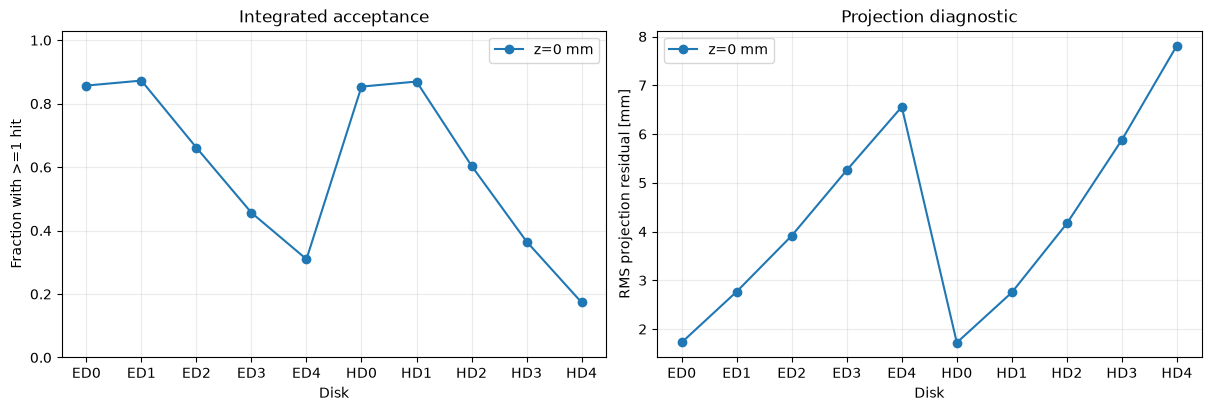

In [35]:
if not integrated.empty:
    fig, axes = plt.subplots(1, 2, figsize=(12, 4), layout='constrained')
    for vertex_z, group in integrated.groupby('vertex_z_mm'):
        axes[0].plot(group.disk, group.acceptance, marker='o', label=f'z={vertex_z:g} mm')
        axes[1].plot(group.disk, group.projection_residual_rms_mm, marker='o',
                     label=f'z={vertex_z:g} mm')
    axes[0].set(ylabel='Fraction with >=1 hit', ylim=(0, 1.03), title='Integrated acceptance')
    axes[1].set(ylabel='RMS projection residual [mm]', title='Projection diagnostic')
    for axis in axes:
        axis.set_xlabel('Disk')
        axis.grid(alpha=.25)
        axis.legend()
    plt.show()

## 6. Generate and display the standard figures

Each vertex produces one integrated plot, two five-row hit/missing pages, and two five-disk acceptance-map pages. Low-statistics acceptance bins are masked.

/global/homes/p/pdatta/.conda/envs/tracking/bin/python /global/cfs/cdirs/m3763/pdatta/epic/proj_svt_disk_tiling/simrec/acc_study/plot_disk_acceptance.py /global/cfs/cdirs/m3763/pdatta/epic/proj_svt_disk_tiling/simrec/acc_study/results/acceptance_v1/reduced/disk_acceptance_vz_000mm.npz --output-dir /global/cfs/cdirs/m3763/pdatta/epic/proj_svt_disk_tiling/simrec/acc_study/results/acceptance_v1/plots --minimum-denominator 50
Plotted /global/cfs/cdirs/m3763/pdatta/epic/proj_svt_disk_tiling/simrec/acc_study/results/acceptance_v1/reduced/disk_acceptance_vz_000mm.npz
Found 5 standard plots
vz_000mm_integrated_acceptance.png


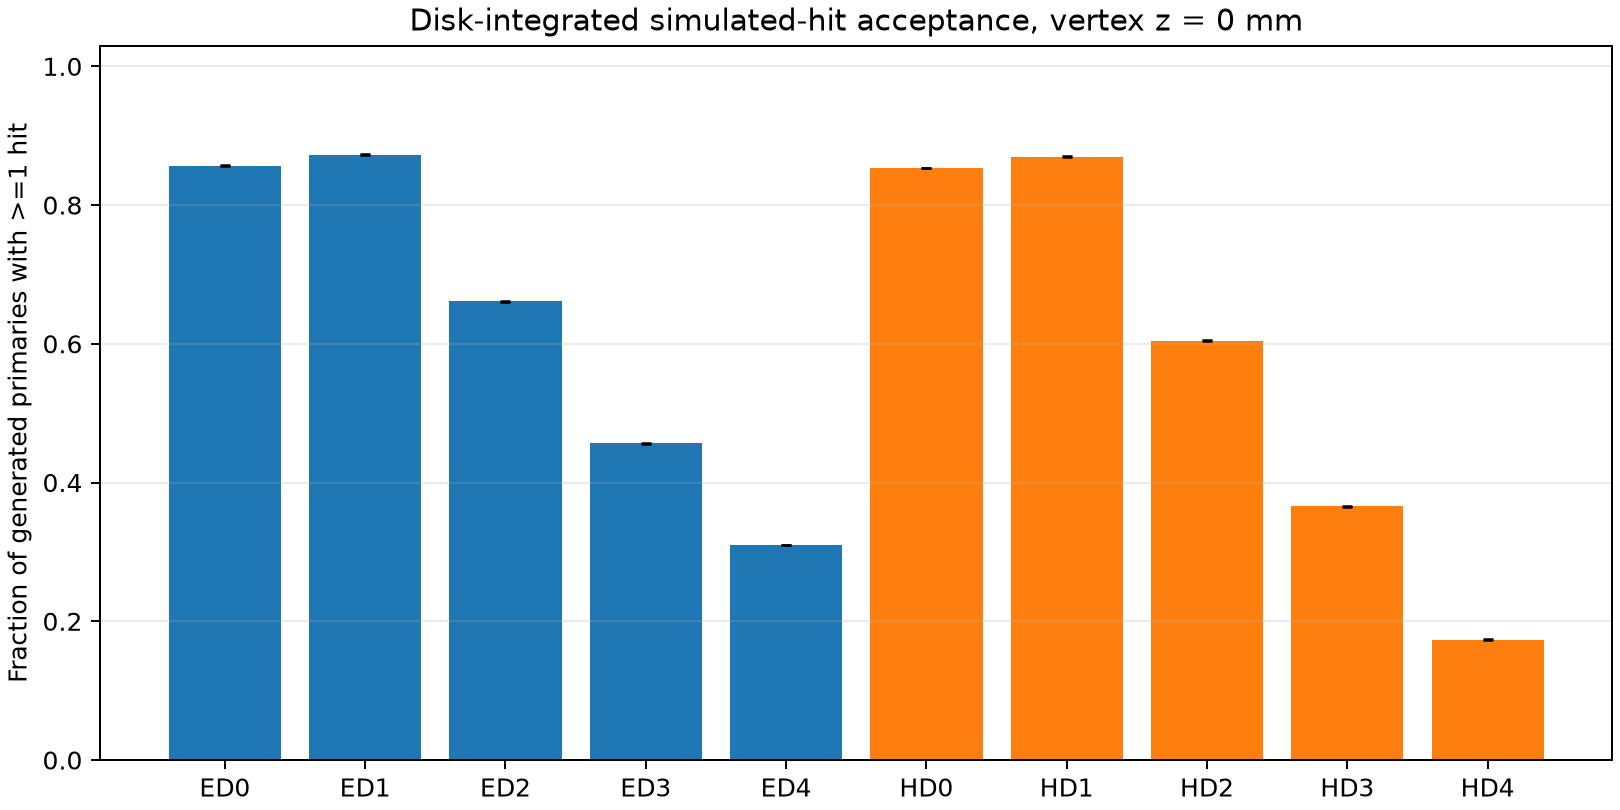

vz_000mm_negative_acceptance_map.png


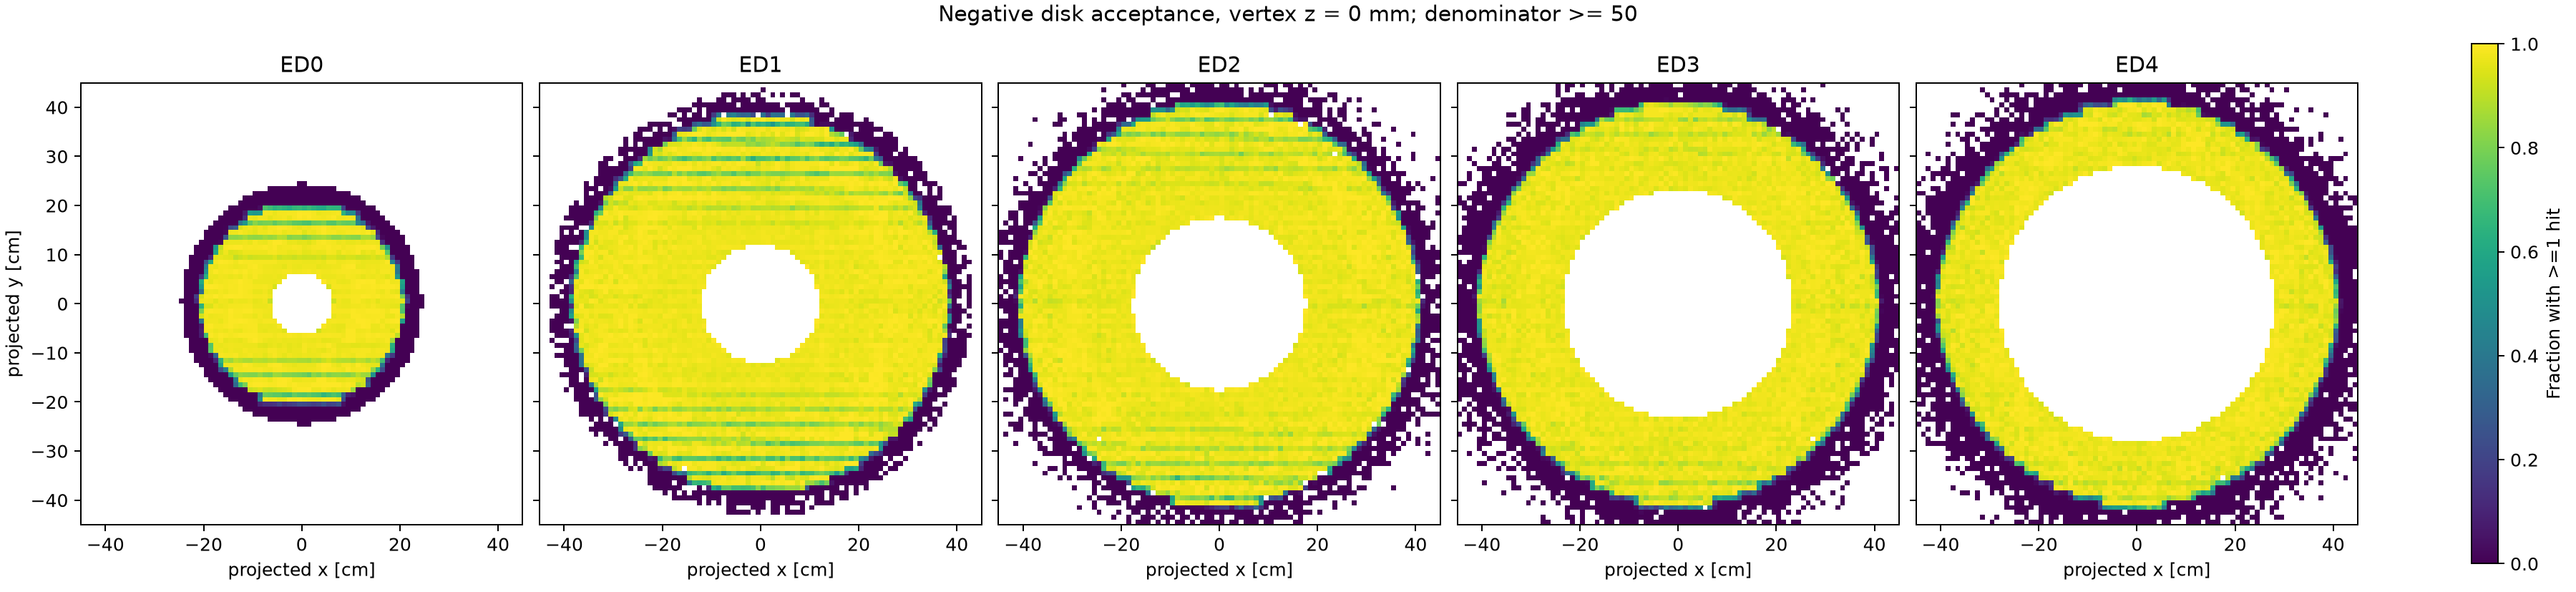

vz_000mm_negative_hit_missing.png


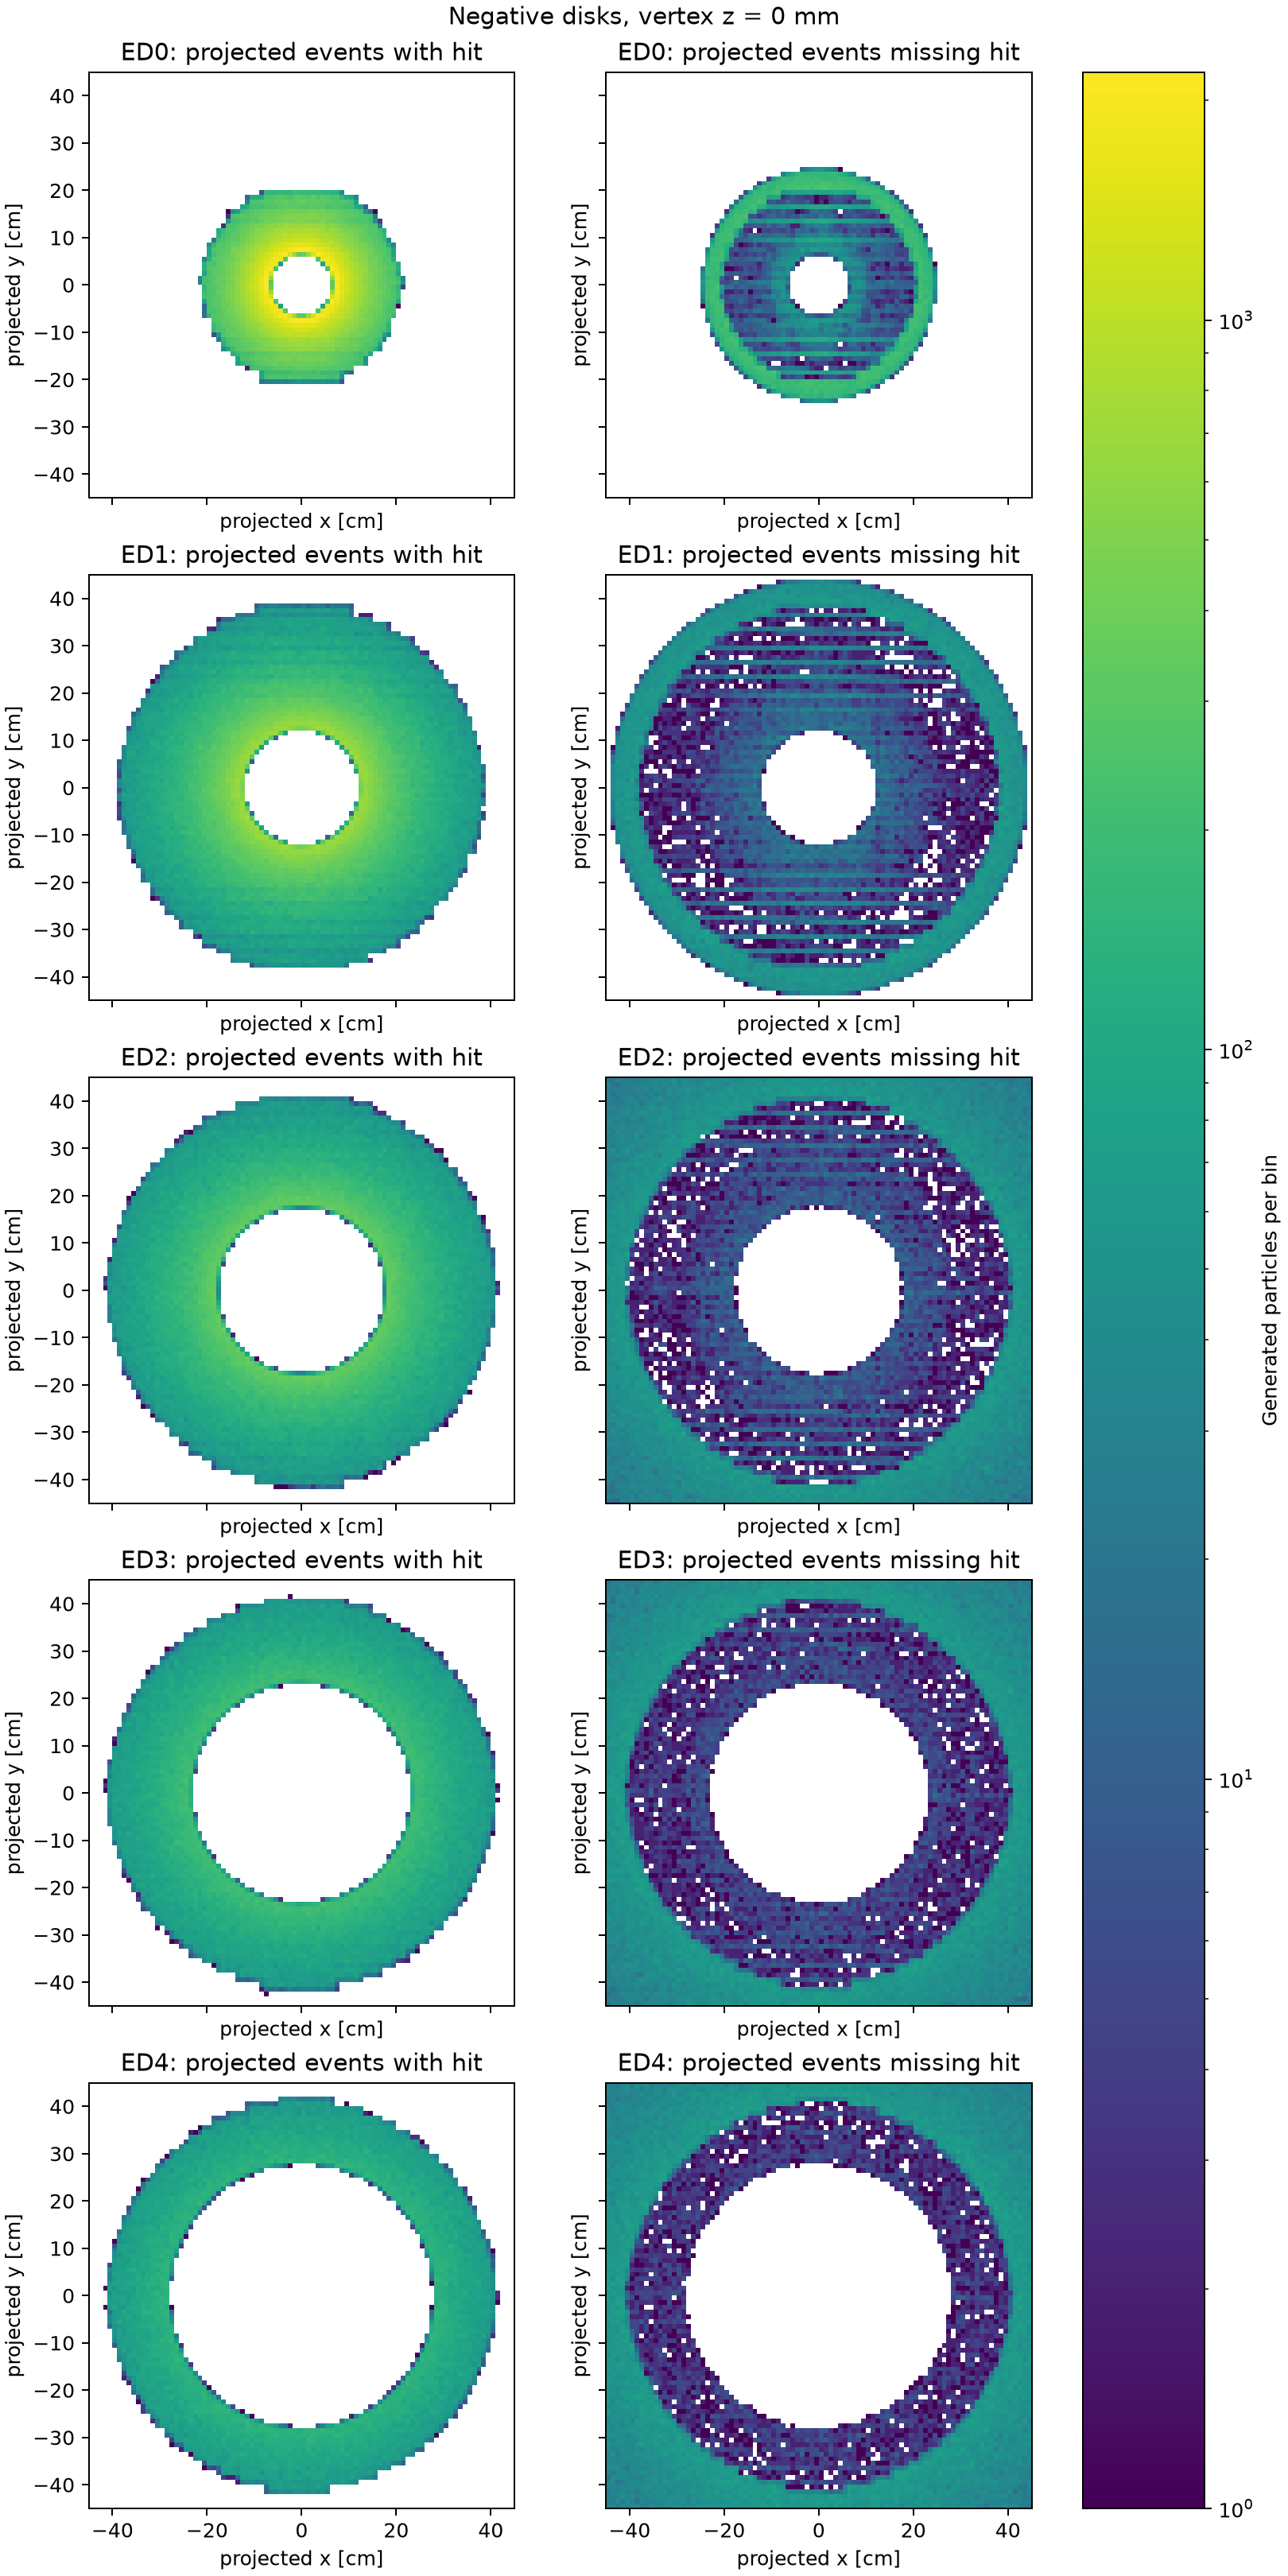

vz_000mm_positive_acceptance_map.png


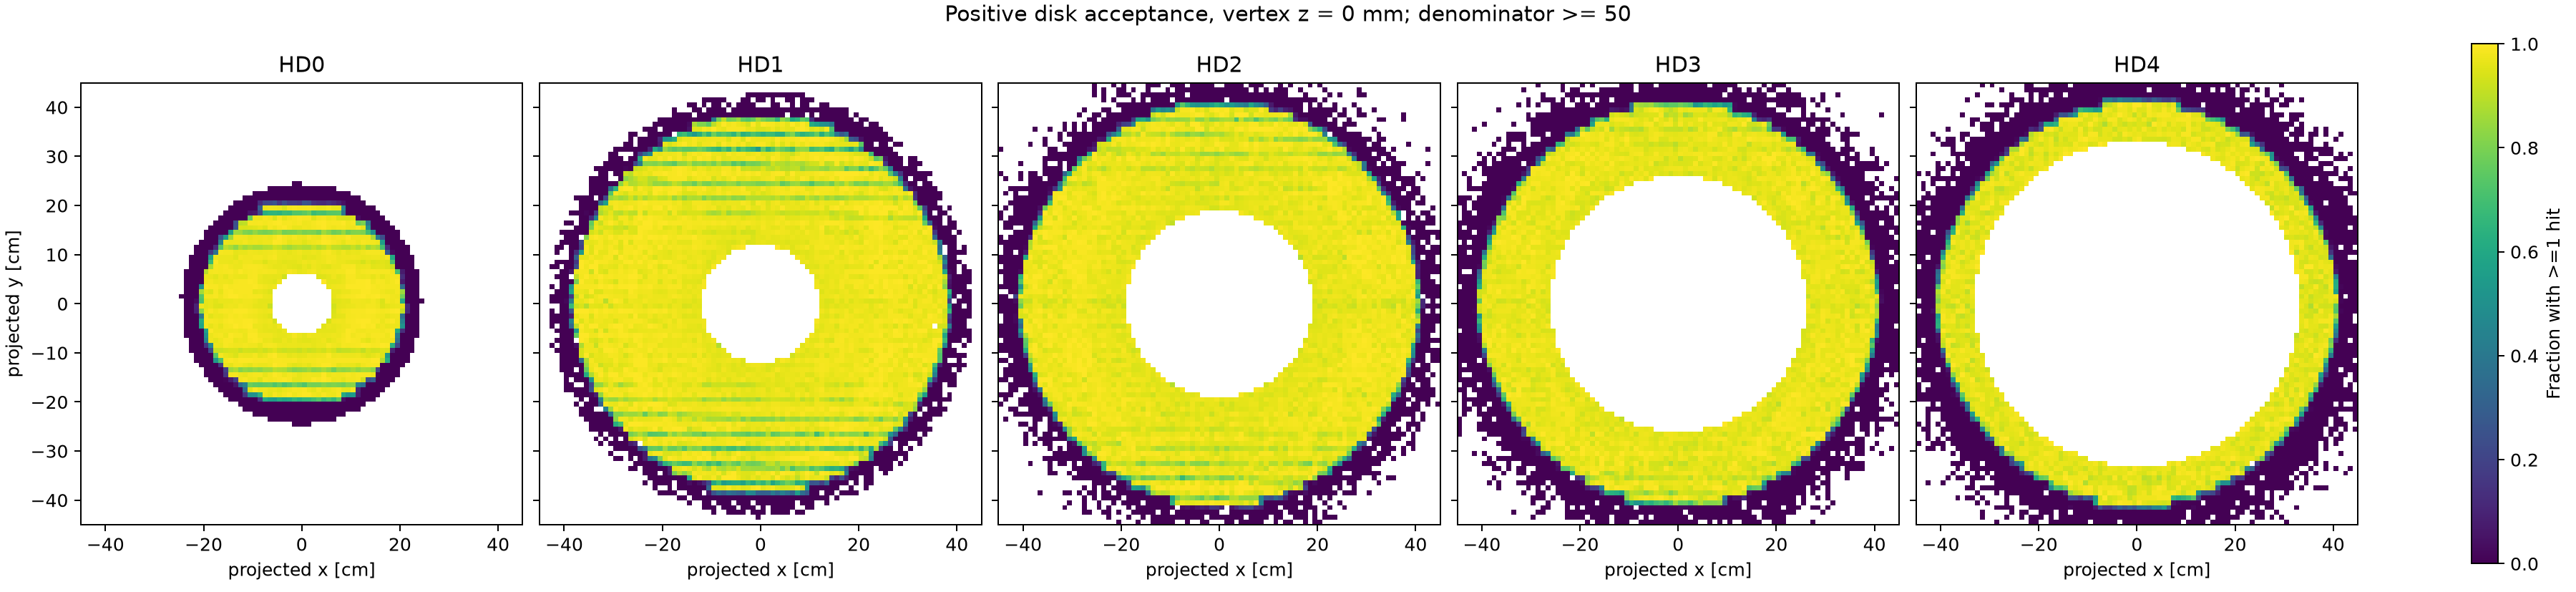

vz_000mm_positive_hit_missing.png


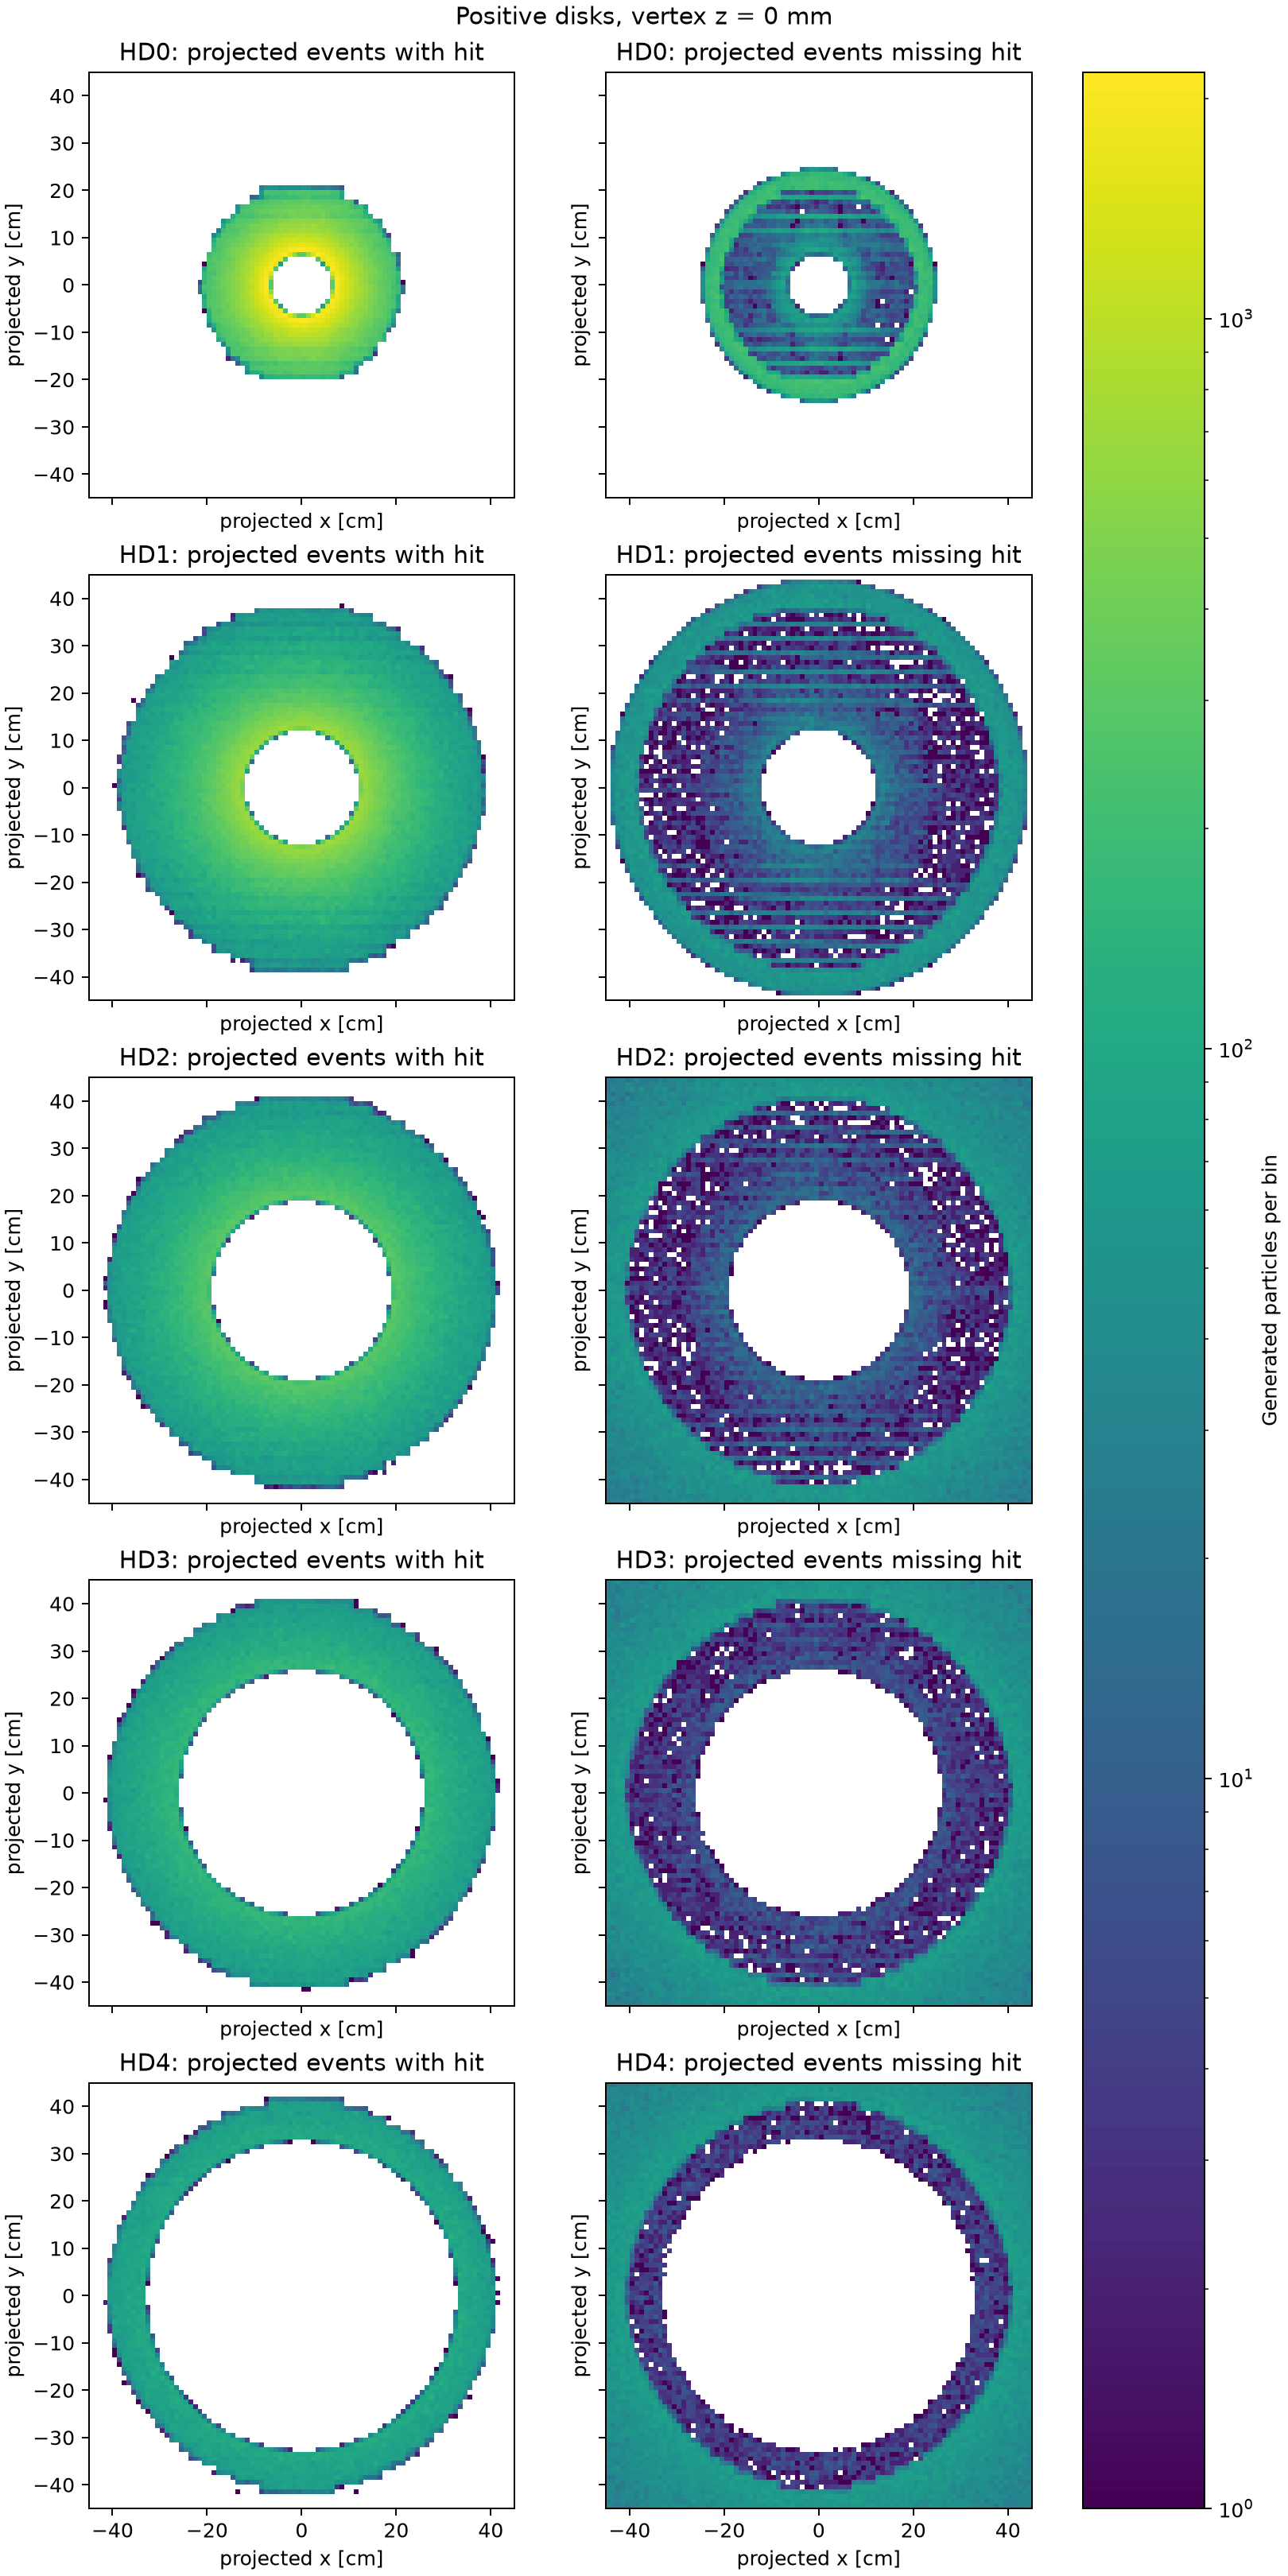

In [36]:
if RUN_STANDARD_PLOTS and npz_files:
    plot_command = [
        sys.executable, str(SCRIPT_DIR / 'plot_disk_acceptance.py'),
        *map(str, npz_files), '--output-dir', str(plot_dir),
        '--minimum-denominator', str(MINIMUM_BIN_DENOMINATOR),
    ]
    print(shlex.join(plot_command))
    subprocess.run(plot_command, check=True)

plot_files = sorted(plot_dir.glob('*.png'))
print(f'Found {len(plot_files)} standard plots')
for path in plot_files:
    print(path.name)
    display(Image(filename=str(path), width=1000))

## 7. Inspect one disk interactively

Choose a reduced vertex file and disk. The first three panels contain all projected denominator, hit, and missing-hit counts. The fourth is their ratio; bins below `MINIMUM_BIN_DENOMINATOR` are masked.

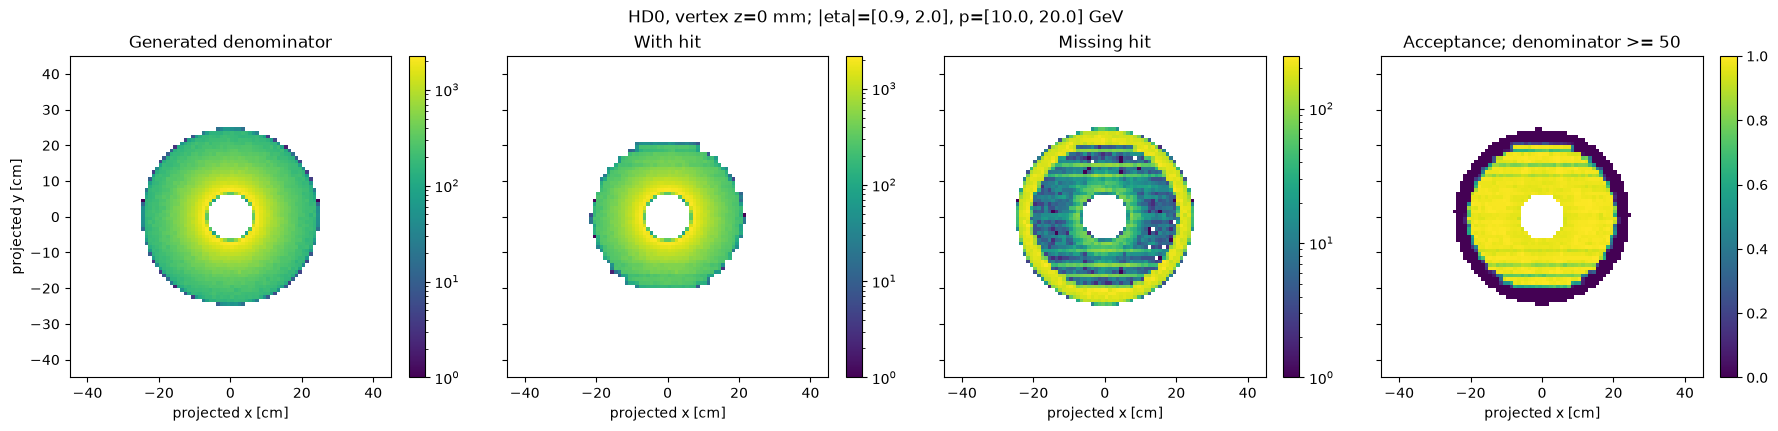

In [37]:
SELECT_VERTEX_MM = 0
SELECT_DISK = 'HD0'

vertex_component = '000' if SELECT_VERTEX_MM == 0 else f"{'p' if SELECT_VERTEX_MM > 0 else 'm'}{abs(SELECT_VERTEX_MM):03d}"
selected_path = reduced_dir / f'disk_acceptance_vz_{vertex_component}mm.npz'
if selected_path.is_file():
    with np.load(selected_path, allow_pickle=False) as stored:
        data = {name: stored[name] for name in stored.files}
    metadata = json.loads(str(data['metadata_json']))
    matches = np.flatnonzero(data['disk_label'] == SELECT_DISK)
    if len(matches) != 1:
        raise ValueError(f'Choose one of {data["disk_label"].tolist()}')
    index = int(matches[0])
    denominator = data['denominator_xy'][index]
    numerator = data['numerator_xy'][index]
    missing = data['missing_xy'][index]
    acceptance = np.divide(numerator, denominator, out=np.zeros_like(numerator, dtype=float),
                           where=denominator > 0)
    masked_acceptance = np.ma.masked_where(denominator < MINIMUM_BIN_DENOMINATOR, acceptance)
    x_edges, y_edges = data['x_edges_mm']/10, data['y_edges_mm']/10

    fig, axes = plt.subplots(1, 4, figsize=(18, 4.2), sharex=True, sharey=True, layout='constrained')
    for axis, counts, title in zip(axes[:3], (denominator, numerator, missing),
                                    ('Generated denominator', 'With hit', 'Missing hit')):
        positive = np.ma.masked_less_equal(counts.T, 0)
        image = axis.pcolormesh(x_edges, y_edges, positive, shading='auto',
                                norm=LogNorm(vmin=1, vmax=max(1, counts.max())))
        fig.colorbar(image, ax=axis)
        axis.set_title(title)
    image = axes[3].pcolormesh(x_edges, y_edges, masked_acceptance.T, shading='auto',
                               vmin=0, vmax=1)
    fig.colorbar(image, ax=axes[3])
    axes[3].set_title(f'Acceptance; denominator >= {MINIMUM_BIN_DENOMINATOR}')
    for axis in axes:
        axis.set_aspect('equal')
        axis.set_xlabel('projected x [cm]')
    axes[0].set_ylabel('projected y [cm]')
    fig.suptitle(f'{SELECT_DISK}, vertex z={SELECT_VERTEX_MM} mm; |eta|={metadata["abs_eta_range"]}, p={metadata["momentum_range_GeV"]} GeV')
    plt.show()
else:
    print(f'No reduced file found: {selected_path}')

## Interpretation checklist

- Integrated acceptance includes geometric coverage: every selected generated primary is in the denominator.
- A particle contributes at most once per disk even if it leaves several hits.
- The 2D coordinate is a generated straight-line projection, not a field-propagated impact point.
- Compare `projection_residual_rms_mm` with `BIN_SIZE_MM` before interpreting fine structure.
- Keep each vertex and each eta/momentum selection in a distinct output directory.
- Empty and low-statistics bins must remain masked, not interpreted as zero acceptance.